# DSCI 552 — Homework 3

- **Name:** Yiming Lu
- **GitHub Username:** YeeDaco

**Instructor:** Mohammad Reza Rajati

All imports are in the first code cell (see `requirements.txt`). The data is loaded by the relative path `../data/AReM/`, so the notebook should be run from the `notebook/` folder.

Problem 3 (ISLR 3.7.3, 3.7.5) is extra practice and Problem 4 belongs to Homework 4, so neither is submitted here.

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import f_classif
import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
pd.set_option("display.max_columns", 50)

## 1. Time Series Classification Part 1: Feature Creation/Extraction

### (a) Load the AReM data

The data is the UCI *Activity Recognition system based on Multisensor data fusion (AReM)* dataset, saved in `../data/AReM/`. There is one folder per activity (`bending1`, `bending2`, `cycling`, `lying`, `sitting`, `standing`, `walking`) and one CSV file per instance. Each file has 5 comment lines starting with `#`, followed by a `time` column and the 6 time series `avg_rss12`, `var_rss12`, `avg_rss13`, `var_rss13`, `avg_rss23`, `var_rss23`.

**Data cleaning.** A few files do not follow the common comma-separated format:

- `bending2/dataset4.csv` is separated by spaces instead of commas.
- `cycling/dataset9.csv` and `cycling/dataset14.csv` have a trailing comma at the end of the rows.
- `sitting/dataset8.csv` has 479 rows instead of 480.

So instead of `pd.read_csv`, each file is parsed line by line: comment lines are skipped and each line is split on any run of commas or whitespace. The raw files are left unchanged. The one missing row is not filled in, because the features below (min, max, mean, quantiles, ...) do not need equal-length series.

In [2]:
DATA_DIR = Path("../data/AReM")
ACTIVITIES = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]
COLUMNS = ["time", "avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]
SERIES = COLUMNS[1:]


def read_arem(path):
    rows = []
    for line in path.read_text().splitlines():
        line = line.strip()
        if not line or line.startswith("#"):
            continue
        values = [v for v in re.split(r"[,\s]+", line) if v]
        rows.append([float(v) for v in values[:7]])
    return pd.DataFrame(rows, columns=COLUMNS)


def file_number(path):
    return int(re.search(r"\d+", path.stem).group())


instances = []
for activity in ACTIVITIES:
    for path in sorted((DATA_DIR / activity).glob("dataset*.csv"), key=file_number):
        instances.append({
            "activity": activity,
            "dataset": file_number(path),
            "data": read_arem(path),
        })

print("number of instances:", len(instances))
lengths = pd.Series({f"{d['activity']}/dataset{d['dataset']}": len(d["data"]) for d in instances})
print("rows per instance:", lengths.value_counts().to_dict())
print("instances with != 480 rows:", lengths[lengths != 480].to_dict())
print("missing values:", sum(int(d["data"].isna().sum().sum()) for d in instances))
pd.Series([d["activity"] for d in instances]).value_counts().reindex(ACTIVITIES).rename("instances")

number of instances: 88
rows per instance: {480: 87, 479: 1}
instances with != 480 rows: {'sitting/dataset8': 479}
missing values: 0


bending1     7
bending2     6
cycling     15
lying       15
sitting     15
standing    15
walking     15
Name: instances, dtype: int64

In [3]:
instances[0]["data"].head()

,time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23
0,0.0000,39.2500,0.4300,22.7500,0.4300,33.7500,1.3000
1,250.0000,39.2500,0.4300,23.0000,0.0000,33.0000,0.0000
2,500.0000,39.2500,0.4300,23.2500,0.4300,33.0000,0.0000
3,750.0000,39.5000,0.5000,23.0000,0.7100,33.0000,0.0000
4,1000.0000,39.5000,0.5000,24.0000,0.0000,33.0000,0.0000


### (b) Train/test split

Datasets 1 and 2 in `bending1` and `bending2`, and datasets 1, 2 and 3 in the other five folders, are the test data. All other files are the training data.

In [4]:
def is_test(activity, dataset):
    if activity in ("bending1", "bending2"):
        return dataset in (1, 2)
    return dataset in (1, 2, 3)


for d in instances:
    d["split"] = "test" if is_test(d["activity"], d["dataset"]) else "train"

split_table = pd.crosstab(
    pd.Series([d["activity"] for d in instances], name="activity"),
    pd.Series([d["split"] for d in instances], name="split"),
    margins=True,
)
split_table

split,test,train,All
activity,,,
bending1,2,5,7
bending2,2,4,6
cycling,3,12,15
lying,3,12,15
sitting,3,12,15
standing,3,12,15
walking,3,12,15
All,19,69,88


### (c) Feature extraction

#### i. Time-domain features commonly used in time series classification

Time-domain features are computed straight from the raw signal values, with no transform to the frequency domain. The ones most often used for sensor and activity-recognition data are:

- **Location / central tendency:** mean, median, mode, trimmed mean.
- **Extremes:** minimum, maximum, range (max − min), peak value, peak-to-peak amplitude.
- **Spread / dispersion:** variance, standard deviation, interquartile range (Q3 − Q1), mean absolute deviation, median absolute deviation, coefficient of variation.
- **Order statistics:** first quartile, third quartile and other percentiles (e.g. 10th, 90th).
- **Shape of the distribution:** skewness, kurtosis.
- **Energy and magnitude:** root mean square (RMS), signal energy (sum of squares), mean absolute value, signal magnitude area.
- **Temporal / dynamic features:** autocorrelation at different lags, zero-crossing rate, mean-crossing rate, number of peaks, slope of a linear trend, mean and std of the first difference, waveform length (sum of absolute differences).
- **Complexity features:** sample entropy, approximate entropy, Hjorth parameters (activity, mobility, complexity).

#### ii. Extract min, max, mean, median, std, Q1 and Q3

For each of the 6 time series of each instance, 7 features are computed, which gives 6 × 7 = 42 features per instance. The standard deviation is the sample standard deviation (ddof = 1). Quartiles use linear interpolation (the NumPy/pandas default). The features are kept on their original scale here; any standardization will be done inside the model pipelines of Homework 4.

In [5]:
STATS = {
    "min": lambda s: s.min(),
    "max": lambda s: s.max(),
    "mean": lambda s: s.mean(),
    "median": lambda s: s.median(),
    "std": lambda s: s.std(),
    "1st quart": lambda s: s.quantile(0.25),
    "3rd quart": lambda s: s.quantile(0.75),
}


def extract_features(df):
    feats = {}
    for i, col in enumerate(SERIES, start=1):
        for name, func in STATS.items():
            feats[f"{name}{i}"] = func(df[col])
    return feats


rows = []
for d in instances:
    rows.append({"activity": d["activity"], "dataset": d["dataset"], "split": d["split"],
                 **extract_features(d["data"])})

features = pd.DataFrame(rows)
features.index = pd.RangeIndex(1, len(features) + 1, name="Instance")
FEATURE_COLS = [c for c in features.columns if c not in ("activity", "dataset", "split")]
print("feature table:", features.shape, "->", len(FEATURE_COLS), "features")
features

feature table: (88, 45) -> 42 features


,activity,dataset,split,min1,max1,mean1,median1,std1,1st quart1,3rd quart1,min2,max2,mean2,median2,std2,1st quart2,3rd quart2,min3,max3,mean3,median3,std3,1st quart3,3rd quart3,min4,max4,mean4,median4,std4,1st quart4,3rd quart4,min5,max5,mean5,median5,std5,1st quart5,3rd quart5,min6,max6,mean6,median6,std6,1st quart6,3rd quart6
Instance,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,bending1,1,test,37.2500,45.0000,40.6248,40.5000,1.4770,39.2500,42.0000,0.0000,1.3000,0.3586,0.4300,0.3226,0.0000,0.5000,4.0000,29.5000,19.0409,19.2500,4.4630,16.0000,23.2500,0.0000,7.2300,0.8325,0.5000,0.9657,0.0000,1.1200,27.2500,38.2500,34.3113,35.0000,2.1884,33.0000,36.0000,0.0000,1.9200,0.5706,0.4300,0.5829,0.0000,1.3000
2,bending1,2,test,38.0000,45.6700,42.8128,42.5000,1.4355,42.0000,43.6700,0.0000,1.2200,0.3724,0.4700,0.2892,0.0000,0.5000,2.0000,29.5000,20.0970,21.0000,3.8937,19.0000,22.2500,0.0000,5.7600,0.8764,0.5000,1.0473,0.0000,1.1450,27.6700,38.5000,33.0246,33.0000,1.9953,32.0000,34.5000,0.0000,3.1100,0.5711,0.4300,0.6010,0.0000,1.3000
3,bending1,3,train,35.0000,47.4000,43.9545,44.3300,1.5588,43.0000,45.0000,0.0000,1.7000,0.4263,0.4700,0.3387,0.0000,0.5000,6.5000,29.7500,22.1224,23.0000,3.0309,19.7500,24.0000,0.0000,4.4400,0.4973,0.4300,0.5507,0.0000,0.8300,29.0000,38.5000,35.5885,36.0000,1.9996,35.3625,36.5000,0.0000,1.7900,0.4933,0.4300,0.5135,0.0000,0.9400
4,bending1,4,train,33.0000,47.7500,42.1798,43.5000,3.6707,39.1500,45.0000,0.0000,3.0000,0.6960,0.5000,0.6309,0.0000,1.1200,8.5000,30.0000,22.1836,23.0000,3.8105,20.5000,24.3725,0.0000,5.1500,0.9899,0.8300,0.9537,0.4300,1.3000,20.0000,38.6700,33.4939,35.0000,3.8494,30.4575,36.3300,0.0000,2.1800,0.6135,0.5000,0.5243,0.0000,1.0000
5,bending1,5,train,33.0000,45.7500,41.6781,41.7500,2.2435,41.3300,42.7500,0.0000,2.8300,0.5360,0.5000,0.4055,0.4300,0.7100,3.0000,28.2500,19.0066,19.1250,4.0871,16.5000,22.0625,0.0000,6.4200,0.8419,0.5000,0.9288,0.4300,1.1200,23.6700,37.5000,29.8571,30.0000,2.4110,28.4575,31.2500,0.0000,1.7900,0.3833,0.4300,0.3892,0.0000,0.5000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,walking,11,train,19.5000,45.3300,33.5869,34.2500,4.6509,30.2500,37.0000,0.0000,14.6700,4.5766,4.2600,2.4611,2.8700,6.1050,7.3300,23.2500,15.3179,15.3300,2.9704,13.2500,17.2700,0.0000,9.0000,3.2272,3.1000,1.6475,2.0500,4.2600,6.3300,25.0000,15.8921,16.0000,3.2840,13.7300,18.2500,0.0000,8.3200,3.2597,3.1100,1.6402,2.0500,4.3225
85,walking,12,train,19.7500,45.5000,34.3227,35.2500,4.7525,31.0000,38.0000,0.0000,13.4700,4.4563,3.9000,2.5993,2.4900,5.9700,6.2500,22.2500,15.2098,15.2500,2.7110,13.5000,17.0000,0.0000,9.0000,3.2772,3.1100,1.5000,2.1700,4.3900,6.2500,23.2500,15.5505,15.7500,3.1199,13.5000,17.7500,0.0000,9.6700,3.4326,3.2000,1.7327,2.1575,4.5650
86,walking,13,train,19.5000,46.0000,34.5462,35.2500,4.8423,31.2500,37.8125,0.0000,12.4700,4.3720,4.1350,2.3604,2.4900,5.8000,7.0000,22.6700,15.1857,15.2500,2.7576,13.2500,17.0000,0.0000,8.3400,3.0287,2.8600,1.6652,1.7900,4.1100,7.0000,22.7500,15.7595,15.7500,2.8231,14.0000,17.7500,0.0000,10.0000,3.3381,3.0800,1.6567,2.1600,4.3350


In [6]:
features.to_csv("../data/arem_time_domain_features.csv")

Here the index `1`–`6` refers to the time series in the order `avg_rss12`, `var_rss12`, `avg_rss13`, `var_rss13`, `avg_rss23`, `var_rss23`. For example `1st quart6` is the first quartile of `var_rss23`. The table is also saved to `../data/arem_time_domain_features.csv` so that Homework 4 can reuse it.

#### iii. Standard deviation of each feature and 90% bootstrap confidence intervals

For each of the 42 features, the standard deviation is estimated over all 88 instances. To get a 90% confidence interval, the 88 instances are resampled with replacement B = 2000 times. The sample standard deviation is recomputed on each bootstrap sample, and the 5th and 95th percentiles of the 2000 values give the interval (percentile bootstrap).

In [7]:
rng = np.random.default_rng(552)
B = 2000
X_all = features[FEATURE_COLS].to_numpy()
n = len(X_all)

boot_idx = rng.integers(0, n, size=(B, n))
boot_std = np.stack([X_all[idx].std(axis=0, ddof=1) for idx in boot_idx])

std_ci = pd.DataFrame({
    "std (estimate)": X_all.std(axis=0, ddof=1),
    "90% CI lower": np.percentile(boot_std, 5, axis=0),
    "90% CI upper": np.percentile(boot_std, 95, axis=0),
}, index=pd.Index(FEATURE_COLS, name="feature"))
std_ci

,std (estimate),90% CI lower,90% CI upper
feature,,,
min1,9.5700,8.2529,10.7615
max1,4.3944,3.3631,5.2696
mean1,5.3357,4.6948,5.9134
median1,5.4401,4.7785,6.0125
std1,1.7722,1.5647,1.9468
1st quart1,6.1536,5.5490,6.6770
3rd quart1,5.1389,4.3561,5.8383
min2,0.0000,0.0000,0.0000
max2,5.0627,4.6387,5.3949


#### iv. The three most important time-domain features

A useful feature should change a lot **between** activities and little **within** an activity. To measure this, I use the one-way ANOVA F-statistic of each feature against the 7 activity labels. The F-statistics are computed **on the training set only**, so the test set is not used to make any choice. Then for each statistic type (min, max, mean, ...) the F-statistic is averaged over the 6 time series.

In [8]:
train = features[features["split"] == "train"]
F, pval = f_classif(train[FEATURE_COLS], train["activity"])
f_table = pd.DataFrame({"feature": FEATURE_COLS, "F": F, "p-value": pval})
f_table["statistic"] = f_table["feature"].str.replace(r"\d+$", "", regex=True)
f_table["series"] = f_table["feature"].str.extract(r"(\d+)$")[0].astype(int)

f_wide = f_table.pivot(index="statistic", columns="series", values="F").reindex(list(STATS))
f_wide.columns = [f"F ({s})" for s in SERIES]
f_wide["mean F"] = f_wide.mean(axis=1)
f_wide["median F"] = f_wide.iloc[:, :6].median(axis=1)
f_wide.sort_values("mean F", ascending=False)

,F (avg_rss12),F (var_rss12),F (avg_rss13),F (var_rss13),F (avg_rss23),F (var_rss23),mean F,median F
statistic,,,,,,,,
mean,15.8545,900.1564,26.3650,651.7610,33.4317,581.4526,368.1702,307.4422
3rd quart,8.5445,807.0489,28.1059,561.8993,32.2417,664.7759,350.4360,297.0705
median,17.4893,477.0135,19.4097,800.7948,28.6376,563.1254,317.7450,252.8255
1st quart,21.3842,265.4565,21.1924,244.8186,25.4939,346.3418,154.1146,135.1562
std,9.1041,360.8948,15.2179,128.6173,7.7774,133.3912,109.1671,71.9176
max,1.5121,47.7273,31.6935,29.3346,36.9528,32.9603,30.0301,32.3269
min,10.9696,NaN,22.7124,NaN,24.0961,0.7760,14.6385,16.8410


Mean, 3rd quartile, median and 1st quartile all score high, but they all measure the *location* of the series, so they carry almost the same information. To check this, the next cell computes the correlation between each pair of statistic types on the training set, averaged over the 6 series. Statistics with zero variance (e.g. `min2`, `min4`, which are always 0) are skipped.

Then the features are chosen greedily: go down the list sorted by mean F, and keep a statistic only if its average |correlation| with every statistic already kept is below 0.9.

In [9]:
stat_names = list(STATS)
corr = pd.DataFrame(index=stat_names, columns=stat_names, dtype=float)
for a in stat_names:
    for b in stat_names:
        pairs = [train[f"{a}{i}"].corr(train[f"{b}{i}"]) for i in range(1, 7)
                 if train[f"{a}{i}"].std() > 0 and train[f"{b}{i}"].std() > 0]
        corr.loc[a, b] = np.mean(pairs)

selected = []
for stat in f_wide.sort_values("mean F", ascending=False).index:
    if all(abs(corr.loc[stat, s]) < 0.9 for s in selected):
        selected.append(stat)
    if len(selected) == 3:
        break
print("selected statistics:", selected)
corr

selected statistics: ['mean', 'std', 'max']


,min,max,mean,median,std,1st quart,3rd quart
min,1.0000,0.3551,0.5915,0.5661,-0.3191,0.6036,0.5205
max,0.3551,1.0000,0.7865,0.7528,0.6278,0.7117,0.8199
mean,0.5915,0.7865,1.0000,0.9907,0.3830,0.9796,0.9806
median,0.5661,0.7528,0.9907,1.0000,0.3626,0.9771,0.9648
std,-0.3191,0.6278,0.3830,0.3626,1.0000,0.2767,0.4975
1st quart,0.6036,0.7117,0.9796,0.9771,0.2767,1.0000,0.9338
3rd quart,0.5205,0.8199,0.9806,0.9648,0.4975,0.9338,1.0000


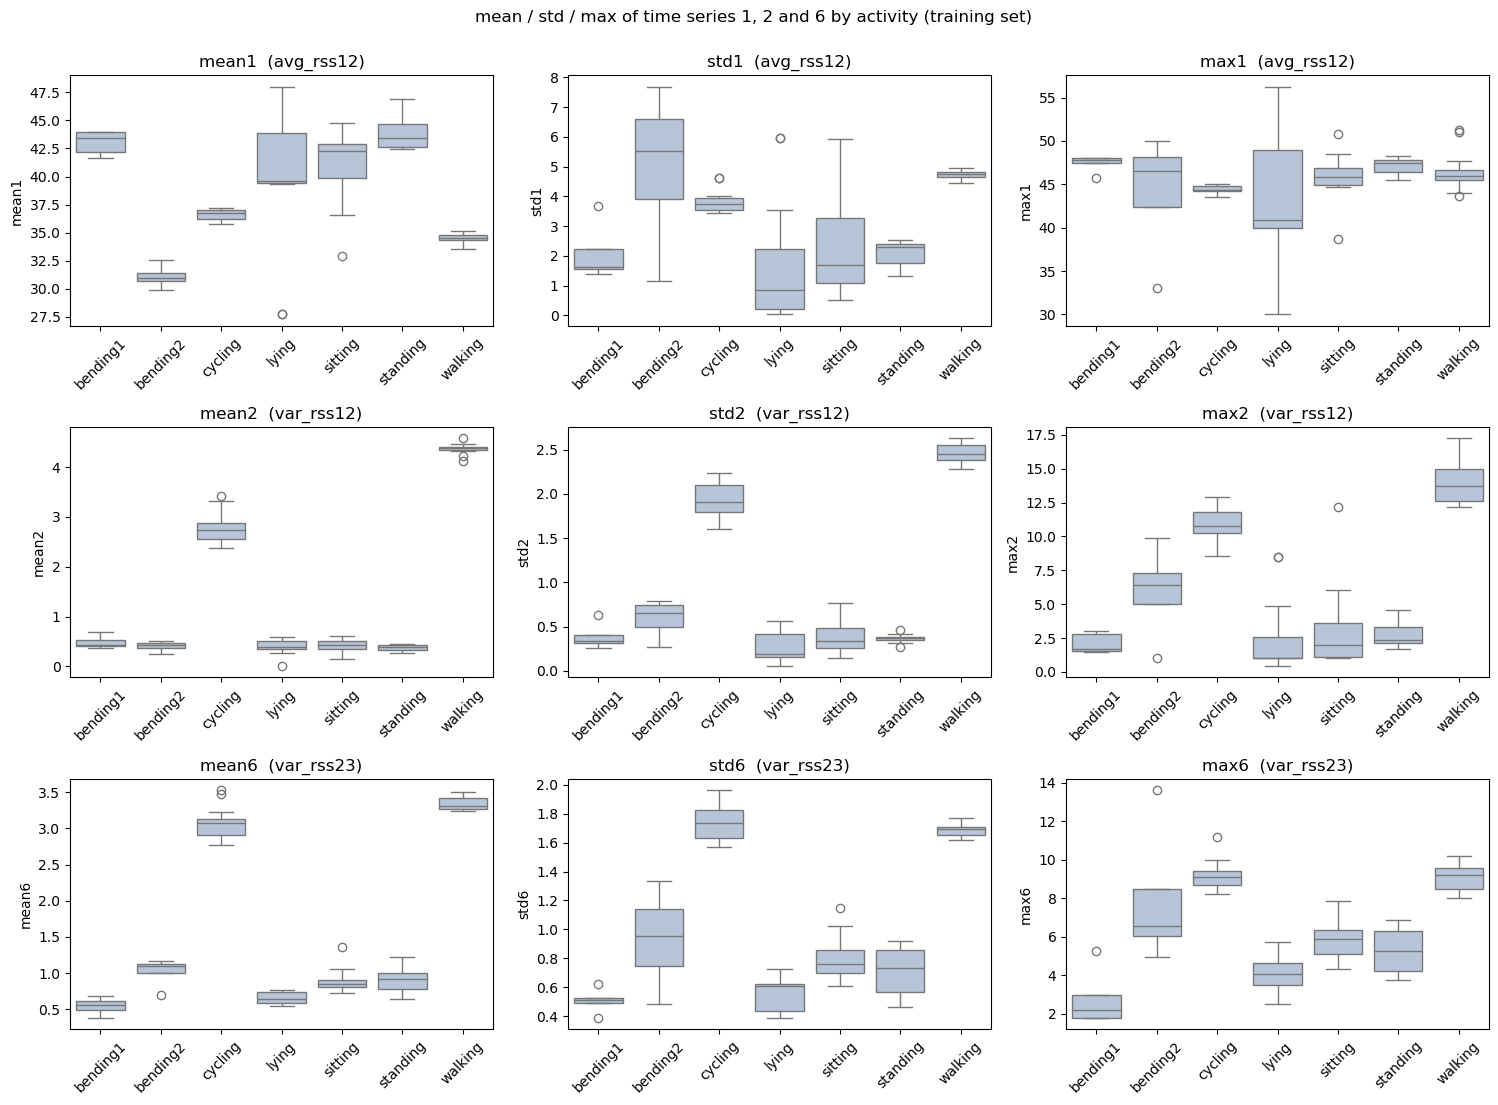

In [10]:
top = selected
fig, axes = plt.subplots(3, 3, figsize=(15, 11), sharey=False)
for r, i in enumerate((1, 2, 6)):
    for c, s in enumerate(top):
        ax = axes[r, c]
        sns.boxplot(data=train, x="activity", y=f"{s}{i}", ax=ax, color="lightsteelblue")
        ax.set_title(f"{s}{i}  ({SERIES[i - 1]})")
        ax.set_xlabel("")
        ax.tick_params(axis="x", rotation=45)
fig.suptitle(f"{' / '.join(top)} of time series 1, 2 and 6 by activity (training set)", y=1.0)
plt.tight_layout()
plt.show()

**Answer — the three selected features are mean, standard deviation and maximum.**

- **Mean** has the highest average F-statistic (≈ 368). It captures the typical signal strength between each pair of sensors, which depends on body posture: lying, sitting and standing put the chest and ankle sensors at different distances. The mean of `var_rss12` and `var_rss13` (F ≈ 900 and 650) also measures the average amount of movement, which separates walking and cycling from the static activities.
- **The 3rd quartile, median and 1st quartile are dropped** even though their F-statistics are high, because their average correlation with the mean is 0.97–0.99. They measure the same thing as the mean.
- **Standard deviation** is the best remaining statistic (mean F ≈ 109) and has a low correlation with the mean (≈ 0.38). It measures how much the signal fluctuates over the 2 minutes, which is information the mean does not have: it is large for dynamic activities and small for static ones.
- **Maximum** is the third choice (mean F ≈ 30). It is less correlated with the mean and std (≈ 0.79 and 0.63) than the quartiles are, and captures the peaks of the signal, e.g. the largest variance bursts during walking or cycling.
- **Minimum** ranks last. For the variance series it is almost always 0 (`min2` and `min4` are constant and `min6` is nearly constant), so it carries very little information.

So my choice is **mean, std and max**. This differs slightly from the suggested *min, mean, max*: on this data the std is clearly more informative than the min. The box plots of the training set above show this, e.g. `mean2` and `std2` separate the dynamic activities (cycling, walking) from the static ones much better than the min would.

## 2. ISLR 3.7.4

*We collect n = 100 observations with one predictor and a quantitative response. We fit a linear regression model Y = β₀ + β₁X + ε, and a separate cubic regression Y = β₀ + β₁X + β₂X² + β₃X³ + ε.*

**(a) The true relationship is linear. Training RSS: linear vs. cubic?**
The cubic training RSS will be **lower (or at worst equal)**. The linear model is a special case of the cubic model with β₂ = β₃ = 0. Least squares minimizes the training RSS, so the cubic fit can always do at least as well as the linear fit on the same data. With noise in the data, the extra terms X² and X³ will fit part of that noise, so the cubic training RSS will in practice be strictly lower.

**(b) The true relationship is linear. Test RSS?**
The linear test RSS is **expected to be lower**. The linear model already matches the true form of f, so it has no bias. The cubic model also has no bias, but its two extra parameters fit noise in the training data, which adds variance and does not reduce bias. That extra variance raises the expected test error. With a particular test set, the cubic model could still have a lower test RSS by chance, but on average the linear model wins.

**(c) The true relationship is not linear (we don't know how far it is). Training RSS?**
The cubic training RSS will be **lower (or equal)**. The reason is the same as in (a): the models are nested, so the more flexible cubic model always fits the training data at least as well. This does not depend on the true relationship.

**(d) The true relationship is not linear. Test RSS?**
**There is not enough information to tell.** It depends on how far the true relationship is from linear, compared with the noise level and n:

- If f is strongly nonlinear, the linear model has a large bias. The cubic model can follow the curvature, so its test RSS is expected to be lower.
- If f is only slightly nonlinear, the drop in bias from the cubic model can be smaller than its extra variance, so the linear model can still have the lower test RSS.

## References

1. G. James, D. Witten, T. Hastie, R. Tibshirani, *An Introduction to Statistical Learning*, Ch. 3 (linear regression, polynomial regression, bias–variance trade-off) and Ch. 5 (bootstrap).
2. UCI Machine Learning Repository — Activity Recognition system based on Multisensor data fusion (AReM): https://archive.ics.uci.edu/ml/datasets/Activity+Recognition+system+based+on+Multisensor+data+fusion+%28AReM%29
3. F. Palumbo, C. Gallicchio, R. Pucci, A. Micheli, *Human activity recognition using multisensor data fusion based on Reservoir Computing*, Journal of Ambient Intelligence and Smart Environments 8(2) (2016) 87–107.
4. B. Efron, R. Tibshirani, *An Introduction to the Bootstrap*, Chapman & Hall, 1993 (percentile intervals).
5. scikit-learn — `f_classif`: https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.f_classif.html